# Tecator: the paper's application, and the same question asked as a parameter

Stefanucci, Bernardi & Canale (2025) close with an application to the Tecator dataset
(their section 62.5). For each of $n = 215$ meat samples they observe a near-infrared
absorbance spectrum $x_i(\omega)$ over $\Omega = [850, 1050]$ nm and a protein content
$y_i$, and fit

$$ y_i = \gamma_0 + \int_\Omega x_i(\omega)\,\psi(\omega)\,d\omega + \varepsilon_i, $$

choosing $\lambda$ "by minimizing the cross-validated prediction error and then applying
the 1-standard error rule". They report that the estimate is **exactly zero above 940 nm**,
so that protein content is determined by $\Omega_1 = [850, 940]$ alone.

This notebook does three things.

1. Reproduces that computation exactly, in `fdaSP.SBC` and again in the authors' own CRAN
   package, and reports what the stated tuning rule actually selects.
2. Locates the penalty at which the paper's null region *does* appear, and measures how far
   that is from where cross-validation stops.
3. Asks the same question a second way. A null set of $[940, 1050]$ is a statement that the
   informative region is a single interval with an unknown right endpoint, which is exactly
   the model of Hall & Hooker (2016). `truncFLR` estimates that endpoint as a parameter, so
   the two approaches can be made to answer each other.

The estimators are `fdaSP.SBC` and `truncFLR.HH`/`truncFLR.HH_A`; the data loader is
`fdaSP.empirical`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from bench import style
from fdaSP import SBC, empirical as emp
from truncFLR import HH, HH_A

style.use(plt)

X, y, wl = emp.load_tecator(target="protein")
grid = np.linspace(0, 1, X.shape[1])      # the normalised domain the B-spline basis lives on
yc = y - y.mean()                         # the paper's gamma_0 handled by centring


def to_nm(t):
    """Normalised domain position -> wavelength in nanometres."""
    return wl[0] + t * (wl[-1] - wl[0])


print(f"n = {X.shape[0]} samples, {X.shape[1]} channels over "
      f"{wl[0]:.0f}-{wl[-1]:.0f} nm")
print(f"protein content {y.min():.1f}% to {y.max():.1f}%, mean {y.mean():.1f}%")

n = 215 samples, 100 channels over 850-1050 nm
protein content 11.0% to 21.8%, mean 17.7%


## 1. What the spectra look like

Colouring each spectrum by the protein content of its sample shows where the response
actually separates the curves. The absorbance level is dominated by a baseline that every
sample shares; what varies with protein is the shape around the two peaks below 1000 nm.

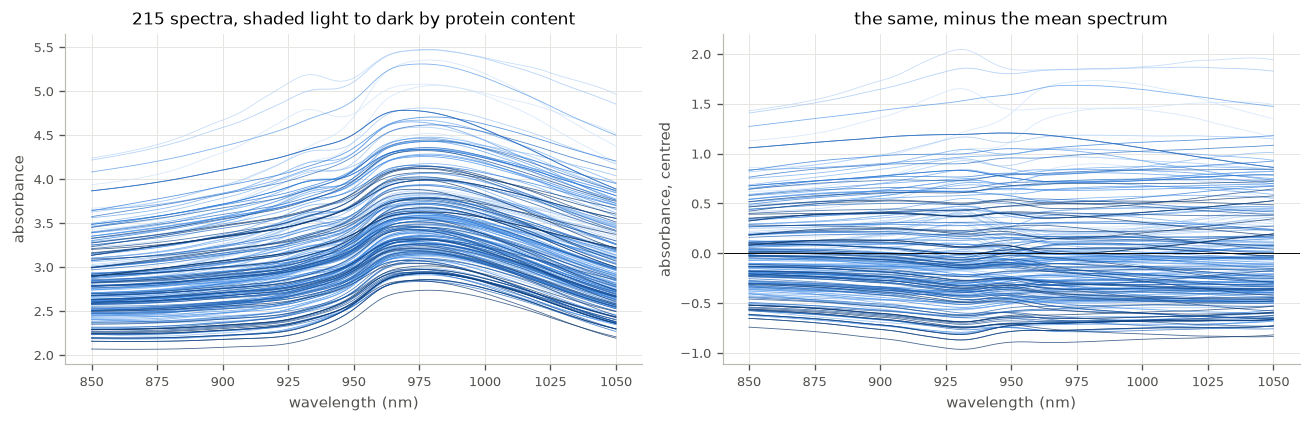

the mean spectrum carries 0.975 of the total squared absorbance


In [2]:
order = np.argsort(y)
colours = style.ordinal(len(y), lightest=0)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for rank, i in enumerate(order):
    ax[0].plot(wl, X[i], color=colours[rank], lw=0.5, alpha=0.75)
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("absorbance")
ax[0].set_title("215 spectra, shaded light to dark by protein content")

# The same curves with the shared baseline removed, which is what the model has to work with
# once an intercept is fitted.
Xc = X - X.mean(axis=0)
for rank, i in enumerate(order):
    ax[1].plot(wl, Xc[i], color=colours[rank], lw=0.5, alpha=0.75)
ax[1].axhline(0, color=style.INK, lw=0.6)
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_ylabel("absorbance, centred")
ax[1].set_title("the same, minus the mean spectrum")
plt.tight_layout()
plt.show()

print(f"the mean spectrum carries {np.mean(X.mean(axis=0) ** 2) / np.mean(X ** 2):.3f} "
      f"of the total squared absorbance")

## 2. The paper's computation, run as written

$M = 15$ basis functions, cubic splines, cross-validated prediction error, then the
one-standard-error rule.

In [3]:
N_BASIS, ORDER, N_FOLDS, N_LAMBDA = 15, 4, 10, 60

cv = SBC.cv_fit(X, yc, grid, n_basis=N_BASIS, order=ORDER, n_folds=N_FOLDS,
                n_lambda=N_LAMBDA, one_se=False, rng=1)
lams, cv_mean, cv_se = cv["lambdas"], cv["cv_mean"], cv["cv_se"]

j_min = int(np.argmin(cv_mean))
j_1se = int(np.argmax(cv_mean <= cv_mean[j_min] + cv_se[j_min]))

print(f"CV-min   lambda = {lams[j_min]:.5g}  (candidate {j_min} of {len(lams) - 1}), "
      f"CV MSE {cv_mean[j_min]:.4f} +- {cv_se[j_min]:.4f}")
print(f"CV-1SE   lambda = {lams[j_1se]:.5g}  (candidate {j_1se}), "
      f"CV MSE {cv_mean[j_1se]:.4f}")

for name, j in (("CV-min", j_min), ("CV-1SE", j_1se)):
    fit = SBC.fit(X, yc, grid, lams[j], n_basis=N_BASIS, order=ORDER)
    print(f"  {name}: {np.mean(~fit['support']) * 100:.0f}% of the domain estimated zero")

CV-min   lambda = 0.0081154  (candidate 59 of 59), CV MSE 1.4143 +- 0.2083
CV-1SE   lambda = 0.023277  (candidate 50), CV MSE 1.6108
  CV-min: 0% of the domain estimated zero
  CV-1SE: 0% of the domain estimated zero


Neither rule zeroes anything. The cross-validated minimum is the *smallest* penalty on the
grid, which is the estimator declining to regularise at all, and the one-standard-error rule
moves it only nine candidates along a sixty-point path.

That is not yet an argument that the paper is wrong. It is an argument that the null region
it reports is not what this tuning rule selects, and the next section locates the penalty
that does produce it.

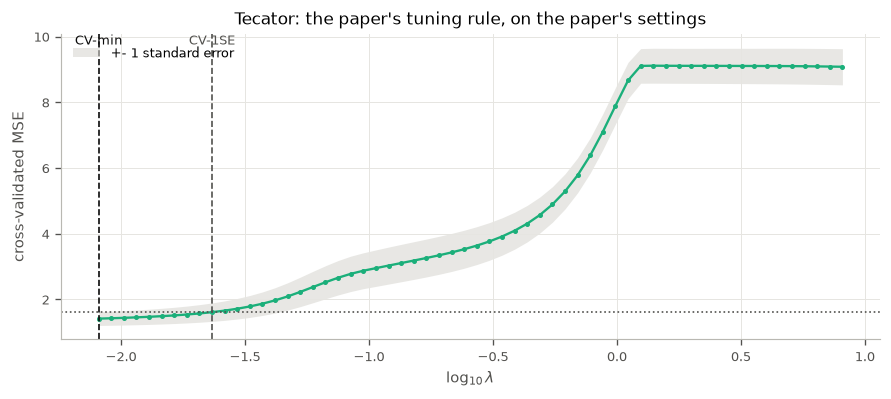

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
lo = np.log10(lams)
ax.fill_between(lo, cv_mean - cv_se, cv_mean + cv_se, color=style.BAND, alpha=0.6,
                lw=0, label="+- 1 standard error")
ax.plot(lo, cv_mean, color=style.METHOD_COLOUR["OGL"], marker=".", ms=4)
ax.axhline(cv_mean[j_min] + cv_se[j_min], color=style.MUTED, ls=":", lw=1)
for j, name, colour in ((j_min, "CV-min", style.INK), (j_1se, "CV-1SE", style.MUTED)):
    ax.axvline(lo[j], color=colour, ls="--", lw=1)
    ax.annotate(name, (lo[j], ax.get_ylim()[1]), color=colour, fontsize=8,
                ha="center", va="top")
ax.set_xlabel(r"$\log_{10}\lambda$")
ax.set_ylabel("cross-validated MSE")
ax.set_title("Tecator: the paper's tuning rule, on the paper's settings")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Where the paper's null region actually lives

The whole path tells a different story from its cross-validated end. Drawing the support as
an image -- one column per penalty, dark where $\hat\psi$ is exactly zero -- shows the order
in which the estimator switches regions off.

In [5]:
path = SBC.fit_path(X, yc, grid, n_basis=N_BASIS, order=ORDER, n_lambda=N_LAMBDA)
zero = ~path["supports"]                             # (n_lambda, n_grid), True where psi = 0
frac = zero.mean(axis=1)
partial = np.where((frac > 0.01) & (frac < 0.99))[0]
print(f"{len(partial)} of {len(path['lambdas'])} penalties leave the estimate partially "
      f"sparse")

# The penalties whose null set is the long-wavelength end, which is the paper's Omega_1.
right = [j for j in partial if zero[j, -1] and not zero[j, 0]]
print("\nnull region at the long-wavelength end:")
for j in right:
    edge = to_nm(grid[zero[j]][0])
    print(f"  lambda = {path['lambdas'][j]:.5g}:  zero above {edge:.0f} nm "
          f"({frac[j] * 100:.0f}% of the domain)")

lam_sparse = float(path["lambdas"][right[0]])
n_se = (np.interp(lam_sparse, lams[::-1], cv_mean[::-1]) - cv_mean[j_min]) / cv_se[j_min]
print(f"\nthe largest such penalty is lambda = {lam_sparse:.5g}, which sits "
      f"{n_se:.2f} standard errors")
print("above the cross-validated minimum. The one-standard-error rule moves 1.")

17 of 60 penalties leave the estimate partially sparse

null region at the long-wavelength end:
  lambda = 0.11989:  zero above 967 nm (42% of the domain)
  lambda = 0.10665:  zero above 967 nm (42% of the domain)
  lambda = 0.094865:  zero above 983 nm (34% of the domain)
  lambda = 0.084383:  zero above 983 nm (34% of the domain)

the largest such penalty is lambda = 0.11989, which sits 7.75 standard errors
above the cross-validated minimum. The one-standard-error rule moves 1.


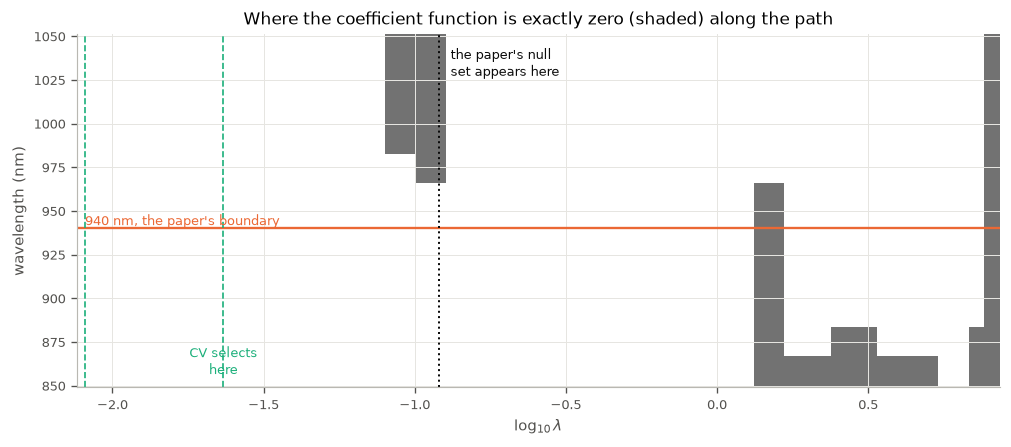

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.pcolormesh(np.log10(path["lambdas"]), wl, zero.T.astype(float),
              cmap="Greys", vmin=0, vmax=1.6, shading="nearest")
ax.axhline(940, color=style.METHOD_COLOUR["HH-B"], lw=1.4, ls="-")
ax.annotate("940 nm, the paper's boundary", (np.log10(lams).min(), 940),
            color=style.METHOD_COLOUR["HH-B"], fontsize=8, va="bottom", ha="left")
for j, name in ((j_min, "CV-min"), (j_1se, "CV-1SE")):
    ax.axvline(np.log10(lams[j]), color=style.METHOD_COLOUR["OGL"], ls="--", lw=1)
ax.axvline(np.log10(lam_sparse), color=style.INK, ls=":", lw=1.2)
ax.annotate("CV selects\nhere", (np.log10(lams[j_1se]), wl[0] + 4),
            color=style.METHOD_COLOUR["OGL"], fontsize=8, ha="center", va="bottom")
ax.annotate("the paper's null\nset appears here", (np.log10(lam_sparse) + 0.04, 1044),
            color=style.INK, fontsize=8, ha="left", va="top")
ax.set_xlabel(r"$\log_{10}\lambda$")
ax.set_ylabel("wavelength (nm)")
ax.set_title("Where the coefficient function is exactly zero (shaded) along the path")
plt.tight_layout()
plt.show()

Read right to left, the estimator first switches off the *short*-wavelength end, holds that
for most of the path, and only in a narrow window near $\lambda \approx 0.1$ switches instead
to the long-wavelength end -- the paper's $[940, 1050]$. Cross-validation stops well to the
left of that window.

The three coefficient functions below are the two the paper's rule returns and the one it
reports.

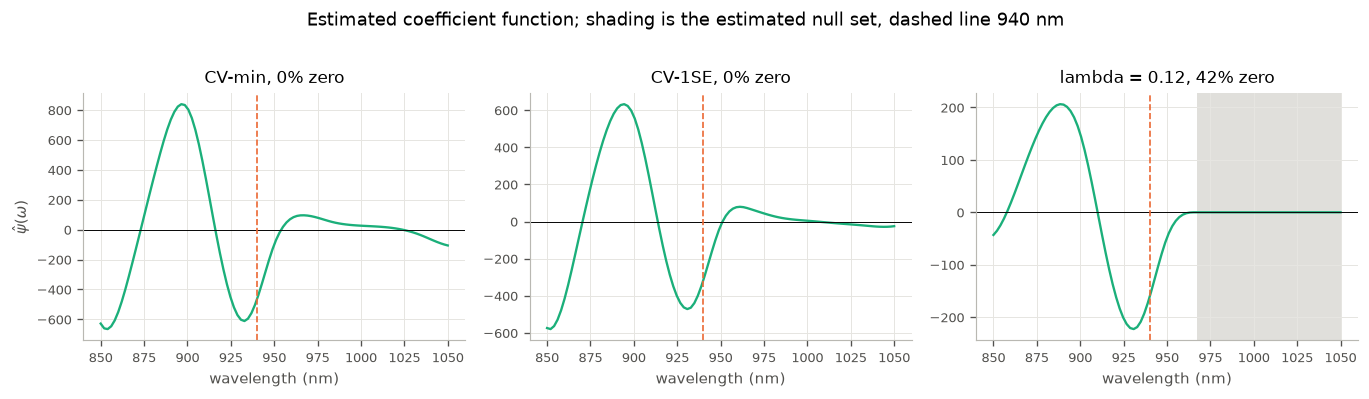

In [7]:
picks = [("CV-min", lams[j_min]), ("CV-1SE", lams[j_1se]),
         (f"lambda = {lam_sparse:.3g}", lam_sparse)]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.2), sharex=True)
for ax, (name, lam) in zip(axes, picks):
    fit = SBC.fit(X, yc, grid, lam, n_basis=N_BASIS, order=ORDER)
    ax.plot(wl, fit["beta"], color=style.METHOD_COLOUR["OGL"])
    ax.axhline(0, color=style.INK, lw=0.6)
    for a, b in SBC.find_regions(~fit["support"], grid):
        ax.axvspan(to_nm(a), to_nm(b), color=style.BAND, alpha=0.8, lw=0)
    ax.axvline(940, color=style.METHOD_COLOUR["HH-B"], lw=1, ls="--")
    ax.set_title(f"{name}, {np.mean(~fit['support']) * 100:.0f}% zero")
    ax.set_xlabel("wavelength (nm)")
axes[0].set_ylabel(r"$\hat\psi(\omega)$")
plt.suptitle("Estimated coefficient function; shading is the estimated null set, "
             "dashed line 940 nm", y=1.02)
plt.tight_layout()
plt.show()

## 4. The authors' own package

`fdaSP.SBC` is a port, so a discrepancy with the paper could be the port rather than the
rule. The check is to run CRAN `fdaSP::f2sSP_cv` -- the function the paper says it used --
on the same data under the same settings. The reference output is committed under
`artifacts/`, so this section runs without R; where R and the package are present the cells
regenerate it instead.

In [8]:
import pandas as pd

from fdaSP import r_reference as rr, rbridge as rb

R_AVAILABLE = rb.r_available("fdaSP")
print(f"R with fdaSP available: {R_AVAILABLE}")
if R_AVAILABLE:
    rr.tecator_cv()

r_cv = pd.read_csv(rr.cached("tecator_f2sSP_cv.csv"))
r_beta = pd.read_csv(rr.cached("tecator_f2sSP_cv_beta.csv")).to_numpy()

i_min, i_1se = int(r_cv["idx_min"][0]) - 1, int(r_cv["idx_1se"][0]) - 1   # R indexes from 1
print(f"f2sSP_cv: {len(r_cv)} penalties, CV-min at candidate {i_min}, "
      f"CV-1SE at candidate {i_1se}")
print(f"  lambda CV-min = {r_cv['lambda'][i_min]:.4g}, "
      f"CV-1SE = {r_cv['lambda'][i_1se]:.4g}")
for k, name in ((0, "CV-1SE"), (1, "CV-min")):
    print(f"  {name} fit: {np.mean(np.abs(r_beta[:, k]) < 1e-8) * 100:.0f}% "
          f"of the domain exactly zero")

R with fdaSP available: True


f2sSP_cv: 80 penalties, CV-min at candidate 79, CV-1SE at candidate 61
  lambda CV-min = 4.407e-05, CV-1SE = 0.0003594
  CV-1SE fit: 0% of the domain exactly zero
  CV-min fit: 0% of the domain exactly zero


In [9]:
print(rr.R_SNIPPETS["tecator_cv"].strip())

suppressMessages(library(fdaSP))
df <- read.csv("{tecator}")
xc <- grep("^x_", names(df), value = TRUE)
X  <- as.matrix(df[, xc]); y <- df$protein
set.seed({seed})
cv <- f2sSP_cv(vY = y, mX = X, M = {M}, standardize.data = TRUE, intercept = FALSE,
               splOrd = {order}, nlambda1 = {n_lambda}, cv.fold = {n_folds})
i   <- which.min(cv$mse)
thr <- cv$mse[i] + cv$mse.sd[i] / sqrt({n_folds})
j   <- min(which(cv$mse <= thr))          # lambda1 descends, so the first is the largest
write.csv(data.frame(lambda = cv$lambda1, mse = cv$mse, mse_sd = cv$mse.sd,
                     idx_min = i, idx_1se = j), "{out_cv}", row.names = FALSE)
fit <- f2sSP(vY = y, mX = X, M = {M}, lambda1 = c(cv$lambda1[j], cv$lambda1[i]),
             standardize.data = TRUE, intercept = FALSE, splOrd = {order})
write.csv(as.data.frame(t(fit$sp.fun.path)), "{out_beta}", row.names = FALSE)


The authors' own package, on their own data, under their own stated rule, returns a fit that
is dense everywhere -- and its cross-validated minimum is the *last* penalty on its path, so
no seed or fold assignment would move it. The port and the original agree about that.

They do not agree about everything, and the difference is instructive. `f2sSP` standardises
the basis-projected design before solving (`fdaSP/README.md` sets out all four conventions
that differ). On spectra as collinear as these, standardising makes every group's norm nearly
equal, so the groups switch off together and the path jumps straight from all-zero to dense
with nothing partially sparse in between. The port, which folds trapezium weights into the
design instead, has the seventeen partially sparse penalties found above. The paper's
$\Omega_1$ is reachable in one parametrisation and not in the other, at the same $M$.

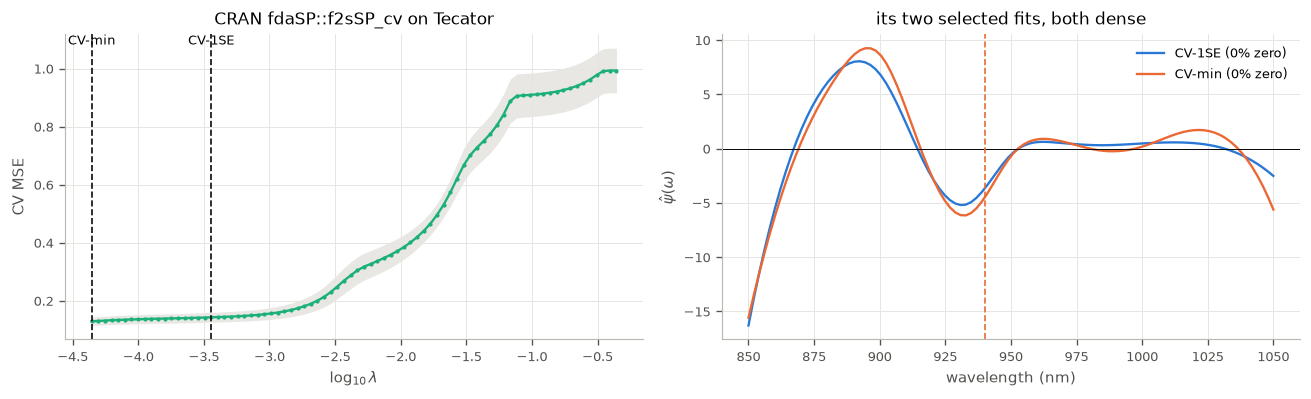

In [10]:
r_lam = np.log10(r_cv["lambda"].to_numpy())
r_zero = np.array([np.mean(np.abs(r_beta[:, k]) < 1e-8) for k in (0, 1)])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].fill_between(r_lam, r_cv["mse"] - r_cv["mse_sd"] / np.sqrt(rr.N_FOLDS_CV),
                   r_cv["mse"] + r_cv["mse_sd"] / np.sqrt(rr.N_FOLDS_CV),
                   color=style.BAND, alpha=0.6, lw=0)
ax[0].plot(r_lam, r_cv["mse"], color=style.METHOD_COLOUR["OGL"], marker=".", ms=3)
for i, name in ((i_min, "CV-min"), (i_1se, "CV-1SE")):
    ax[0].axvline(r_lam[i], color=style.INK, ls="--", lw=1)
    ax[0].annotate(name, (r_lam[i], ax[0].get_ylim()[1]), fontsize=8, ha="center", va="top")
ax[0].set_xlabel(r"$\log_{10}\lambda$")
ax[0].set_ylabel("CV MSE")
ax[0].set_title("CRAN fdaSP::f2sSP_cv on Tecator")

for k, name in ((0, "CV-1SE"), (1, "CV-min")):
    ax[1].plot(wl, r_beta[:, k], label=f"{name} ({r_zero[k] * 100:.0f}% zero)")
ax[1].axhline(0, color=style.INK, lw=0.6)
ax[1].axvline(940, color=style.METHOD_COLOUR["HH-B"], ls="--", lw=1)
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_ylabel(r"$\hat\psi(\omega)$")
ax[1].set_title("its two selected fits, both dense")
ax[1].legend()
plt.tight_layout()
plt.show()

## 5. The same question asked as a parameter

"Zero above 940 nm" is a statement that the informative region is one interval, $[850,
\theta]$, with $\theta$ unknown. That is Hall & Hooker's model, and `truncFLR` estimates
$\theta$ directly rather than reading it off whichever basis groups a penalty switched off.

In [11]:
lambdas = np.linspace(0.0, 1.0, 120)[1:]

print(f"lambda searched over {len(lambdas)} candidates in "
      f"[{lambdas[0]:.4g}, {lambdas[-1]:.4g}]\n")
for name, module in (("method B", HH), ("method A", HH_A)):
    res = module.fit(X, yc, grid, lambdas)
    print(f"{name}: theta_hat = {res['theta_hat']:.3f} -> {to_nm(res['theta_hat']):.0f} nm, "
          f"keeping {res['theta_hat'] * 100:.0f}% of the domain")
    print(f"          lambda_hat = {res['lam_hat']:.4g}, at quantile "
          f"{np.mean(lambdas <= res['lam_hat']):.2f} of the candidate grid")

lambda searched over 119 candidates in [0.008403, 1]



method B: theta_hat = 0.091 -> 868 nm, keeping 9% of the domain
          lambda_hat = 0.958, at quantile 0.96 of the candidate grid


method A: theta_hat = 0.343 -> 919 nm, keeping 34% of the domain
          lambda_hat = 0.05042, at quantile 0.05 of the candidate grid


The two methods disagree, and they disagree in the way section 3.2 predicts they will.

Method A lands at 919 nm, close to the paper's 940 and, as the next section shows, close to
what held-out prediction says as well. Method B lands at 868 nm, keeping under a tenth of the
domain, and it gets there on a penalty in the top few per cent of its candidate grid. That is
the degeneracy `notebooks/truncFLR_lambdadegen.ipynb` works through: over much of its range
the selection criterion is monotone in $\lambda$, so it drifts towards a grid endpoint and
drags $\hat\theta$ with it. On simulated data that failure is visible because the truth is
known. Here it is not, so agreement between the two methods cannot be assumed, and the
endpoint has to be established some other way.

## 6. Reading the boundary off held-out prediction

`truncFLR.HH_A.truncation_profile` fits the truncated model at each candidate $\theta$ and
scores it by cross-validated prediction error. No tuning parameter and no asymptotics are
involved; the question "where does the informative region end" is answered by what the
retained region can predict.

The profile has to be read at its elbow rather than at its minimum. Past the true endpoint
the extra stretch carries no signal, so keeping it costs a little estimation variance and
nothing else, and the error flattens instead of rising -- the minimiser then wanders over
that flat region. The one-standard-error elbow asks where the error *stopped falling*, which
is the question the endpoint answers, and `tests/test_hh_a.py` checks that it recovers a
known endpoint on simulated data where the minimiser does not.

In [12]:
prof = HH_A.truncation_profile(X, yc, grid, n_folds=N_FOLDS, rng=1)

print(f"minimiser    theta = {prof['theta_hat']:.3f} -> {to_nm(prof['theta_hat']):.0f} nm")
print(f"1-SE elbow   theta = {prof['theta_1se']:.3f} -> {to_nm(prof['theta_1se']):.0f} nm")
print("the paper reports 940 nm\n")

best = int(np.argmin(prof["mse"]))
within = np.isfinite(prof["mse"]) & (prof["mse"] <= prof["mse"][best] + prof["se"][best])
admissible = prof["thetas"][within]
print(f"endpoints within one standard error of the best: "
      f"{to_nm(admissible.min()):.0f}-{to_nm(admissible.max()):.0f} nm")
print(f"held-out MSE at the best truncation : {prof['mse'][best]:.3f}")
print(f"held-out MSE keeping the whole range: {prof['mse_full']:.3f}")
print(f"truncating cuts held-out error by "
      f"{100 * (1 - prof['mse'][best] / prof['mse_full']):.0f}%")

minimiser    theta = 0.374 -> 925 nm
1-SE elbow   theta = 0.323 -> 915 nm
the paper reports 940 nm

endpoints within one standard error of the best: 915-965 nm
held-out MSE at the best truncation : 0.625
held-out MSE keeping the whole range: 0.989
truncating cuts held-out error by 37%


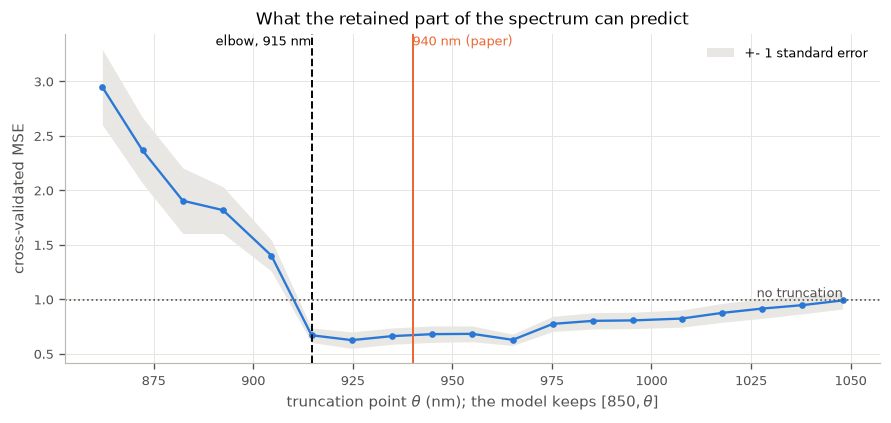

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
# The shortest candidate windows cannot support a truncated FPCA and score infinity, so they
# are left out of the drawing rather than stretching the axis to meet them.
ok = np.isfinite(prof["mse"]) & np.isfinite(prof["se"])
nm_grid, mse, se = to_nm(prof["thetas"][ok]), prof["mse"][ok], prof["se"][ok]
ax.fill_between(nm_grid, mse - se, mse + se,
                color=style.BAND, alpha=0.6, lw=0, label="+- 1 standard error")
ax.plot(nm_grid, mse, color=style.METHOD_COLOUR["HH-A"], marker=".")
ax.axhline(prof["mse_full"], color=style.MUTED, ls=":", lw=1)
ax.annotate("no truncation", (nm_grid[-1], prof["mse_full"]), fontsize=8,
            ha="right", va="bottom", color=style.MUTED)
ax.axvline(to_nm(prof["theta_1se"]), color=style.INK, ls="--", lw=1.2)
ax.annotate(f"elbow, {to_nm(prof['theta_1se']):.0f} nm",
            (to_nm(prof["theta_1se"]), ax.get_ylim()[1]), fontsize=8, ha="right", va="top")
ax.axvline(940, color=style.METHOD_COLOUR["HH-B"], lw=1.2)
ax.annotate("940 nm (paper)", (940, ax.get_ylim()[1]), fontsize=8, ha="left", va="top",
            color=style.METHOD_COLOUR["HH-B"])
ax.set_xlabel(r"truncation point $\theta$ (nm); the model keeps $[850, \theta]$")
ax.set_ylabel("cross-validated MSE")
ax.set_title("What the retained part of the spectrum can predict")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Which end carries the signal

The paper keeps the short-wavelength end. The same profile run in the other orientation asks
whether $[u, 1050]$ would do as well, and settles the question by prediction rather than by
assertion.

keeping [850, theta] : best held-out MSE 0.625 at 925 nm
keeping [u, 1050]    : best held-out MSE 0.858 at 882 nm
no truncation        :      held-out MSE 0.989


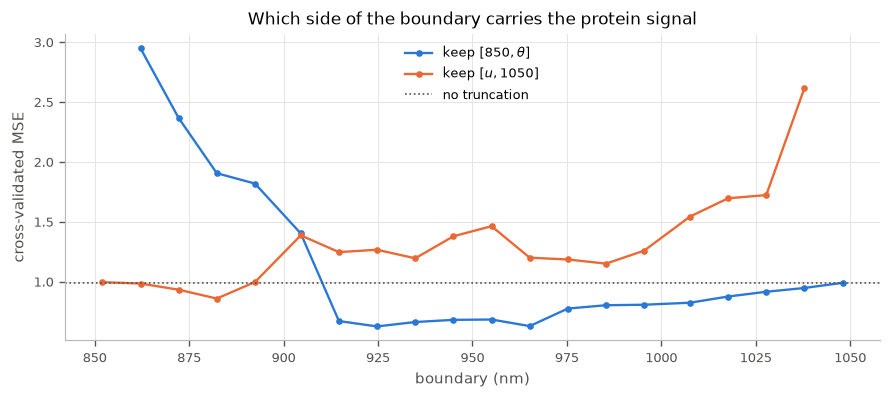

In [14]:
prof_m = HH_A.truncation_profile(X, yc, grid, n_folds=N_FOLDS, rng=1, mirror=True)

print(f"keeping [850, theta] : best held-out MSE {np.nanmin(prof['mse']):.3f} "
      f"at {to_nm(prof['theta_hat']):.0f} nm")
print(f"keeping [u, 1050]    : best held-out MSE {np.nanmin(prof_m['mse']):.3f} "
      f"at {to_nm(prof_m['theta_hat']):.0f} nm")
print(f"no truncation        :      held-out MSE {prof['mse_full']:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for p, colour, lab in ((prof, style.METHOD_COLOUR["HH-A"], r"keep $[850, \theta]$"),
                       (prof_m, style.METHOD_COLOUR["HH-B"], r"keep $[u, 1050]$")):
    good = np.isfinite(p["mse"])
    ax.plot(to_nm(p["thetas"][good]), p["mse"][good], color=colour, marker=".", label=lab)
ax.axhline(prof["mse_full"], color=style.MUTED, ls=":", lw=1, label="no truncation")
ax.set_xlabel("boundary (nm)")
ax.set_ylabel("cross-validated MSE")
ax.set_title("Which side of the boundary carries the protein signal")
ax.legend()
plt.tight_layout()
plt.show()

Keeping the short-wavelength end is decisively better, and it is better than keeping
everything. The paper's reading of the domain is the right one; what the group lasso could
not do on this data is select it.

## 7. The two approaches, and what separates them

Both estimators put the boundary in the same place. They disagree about what it costs, and
the reason is worth stating plainly.

In [15]:
folds = np.random.default_rng(3).permutation(len(y)) % N_FOLDS


def ogl_holdout(lam):
    """Held-out MSE of the group lasso at a fixed penalty, on the shared folds."""
    err = 0.0
    for f in range(N_FOLDS):
        te, tr = folds == f, folds != f
        mu = y[tr].mean()
        fit = SBC.fit(X[tr], y[tr] - mu, grid, lam, n_basis=N_BASIS, order=ORDER)
        err += np.sum((y[te] - (SBC.predict(fit, X[te], grid) + mu)) ** 2)
    return err / len(y)


rows = [("OGL at CV-min", lams[j_min]), ("OGL at CV-1SE", lams[j_1se]),
        ("OGL at the sparse penalty", lam_sparse)]
print(f"{'estimator':30s}{'held-out MSE':>14}{'domain zeroed':>15}")
for name, lam in rows:
    fit = SBC.fit(X, yc, grid, lam, n_basis=N_BASIS, order=ORDER)
    print(f"{name:30s}{ogl_holdout(lam):14.3f}{np.mean(~fit['support']) * 100:14.0f}%")
zeroed = 100 * (1 - prof["theta_1se"])
print(f"{'truncated model at the elbow':30s}{np.min(prof['mse']):14.3f}{zeroed:14.0f}%")

estimator                       held-out MSE  domain zeroed


OGL at CV-min                          1.418             0%


OGL at CV-1SE                          1.622             0%


OGL at the sparse penalty              3.037            42%
truncated model at the elbow           0.625            68%


The group lasso can reach the paper's null set, but only by shrinking everything it keeps at
the same time: one $\lambda$ controls both. Reaching 42% sparsity therefore more than
doubles its held-out error. The truncation model separates the two decisions -- it estimates
where to cut, then fits the retained interval without shrinkage -- and so buys the same
support at a held-out error *below* the untruncated fit.

That is the trade the two models make with each other, seen on real data: the penalty gives
up an explicit boundary and pays for sparsity in bias; the truncation model gives up the
ability to find more than one interval and pays for it in the tuning problem of section 3.2,
which on this data does not work.

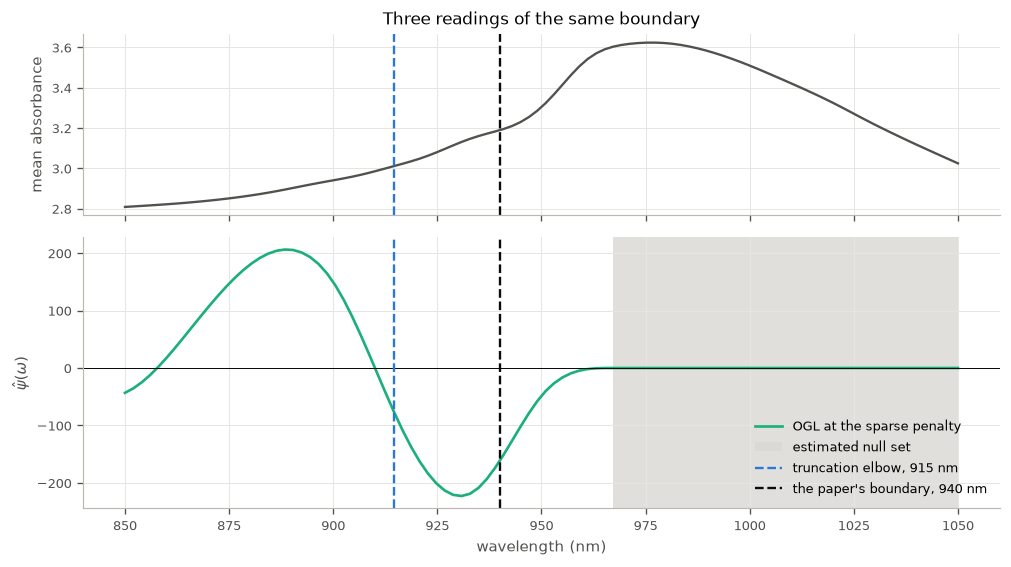

In [16]:
fit_sparse = SBC.fit(X, yc, grid, lam_sparse, n_basis=N_BASIS, order=ORDER)
boundaries = ((to_nm(prof["theta_1se"]), style.METHOD_COLOUR["HH-A"], "truncation elbow"),
              (940.0, style.INK, "the paper's boundary"))

fig, ax = plt.subplots(2, 1, figsize=(8.5, 4.8), sharex=True,
                       gridspec_kw={"height_ratios": [1, 1.5]})

ax[0].plot(wl, X.mean(axis=0), color=style.MUTED, lw=1.4)
ax[0].set_ylabel("mean absorbance")
ax[0].set_title("Three readings of the same boundary")

ax[1].plot(wl, fit_sparse["beta"], color=style.METHOD_COLOUR["OGL"], lw=1.6,
           label="OGL at the sparse penalty")
for k, (a, b) in enumerate(SBC.find_regions(~fit_sparse["support"], grid)):
    ax[1].axvspan(to_nm(a), to_nm(b), color=style.BAND, alpha=0.8, lw=0,
                  label="estimated null set" if k == 0 else None)
ax[1].axhline(0, color=style.INK, lw=0.6)
ax[1].set_ylabel(r"$\hat\psi(\omega)$")
ax[1].set_xlabel("wavelength (nm)")

for value, colour, label in boundaries:
    for panel in ax:
        panel.axvline(value, color=colour, ls="--", lw=1.4)
    ax[1].plot([], [], color=colour, ls="--", lw=1.4, label=f"{label}, {value:.0f} nm")
ax[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

The boundary all three put near 940 nm is not an artefact of any of them. It is where the
water and fat absorption bands sit in a near-infrared spectrum; above it the spectra are
dominated by features that vary with the sample's water content rather than its protein, and
the estimators are finding a real property of the measurement.

## Summary

**The paper's null region is real, and its tuning rule does not select it.** Run as written
-- $M = 15$, cross-validated error, then the one-standard-error rule -- neither `fdaSP.SBC`
nor the authors' own CRAN `f2sSP_cv` zeroes any part of the domain, and `f2sSP_cv`'s minimum
is the last penalty on its own path. The null set the paper reports does appear along the
port's path, at a penalty sitting some eight standard errors above the cross-validated
minimum where the one-standard-error rule moves one.

**Two conventions decide whether it is reachable at all.** Standardising the basis-projected
design, as `f2sSP` does, makes the group norms of these highly collinear spectra nearly
equal, so the path jumps from all-zero to dense with nothing partially sparse in between. The
port's trapezium weighting leaves seventeen partially sparse penalties. Same estimator, same
$M$, same data.

**The truncation model reaches the same boundary from prediction alone**, where its own
section 3.2 criterion does not -- method A puts the endpoint at 919 nm, method B collapses to
868 nm on a penalty near the top of its grid. Held-out error
falls steeply up to about 915 nm and is flat from there to 965 nm, so 940 nm is inside the
interval the data cannot distinguish from the best. Truncating cuts held-out error by around
a third against keeping the whole spectrum, and keeping the long-wavelength end instead is
clearly worse -- the paper's reading of which side matters is confirmed.

**What the two models pay is different.** The group lasso ties the location of the null set
to the shrinkage on everything it keeps, so on this data the sparsity the paper reports more
than doubles its held-out error. The truncation model decides where to cut and then
fits the retained interval freely, and reaches the same support at a held-out error below the
untruncated fit. Its own tuning rule, section 3.2, does not find that point; the held-out
profile does.